<a href="https://colab.research.google.com/github/Pradeep752007/qskill-python-internship/blob/main/Task2_House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading California Housing dataset...

Dataset loaded successfully!
Dataset shape: (20640, 9)

First five rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Missing values in each column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate rows: 0

Preprocessing completed.
Features shape: (20640, 8)
Target shape: (20640,)

Training samples: 16512
Testing samples: 4128

Linear Regression model trained successfully!

Sample predictions:


,Actual_Value_100k_USD,Predicted_Value_100k_USD
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615



MODEL PERFORMANCE
------------------------------
Mean Absolute Error (MAE): 0.5332
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error:   0.7456
R-squared Score:           0.5758

Interpretation:
MAE and RMSE measure prediction error.
R-squared measures how much variation the model explains.
A higher R-squared is generally better.


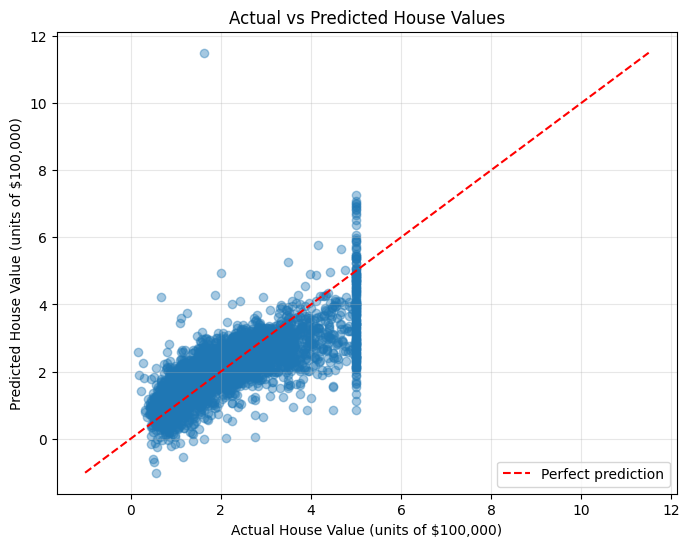


Feature coefficients:


,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
7,Longitude,-0.433708
6,Latitude,-0.419792
2,AveRooms,-0.123323
1,HouseAge,0.009724
5,AveOccup,-0.003526
4,Population,-0.000002



SAMPLE HOUSE PREDICTION
------------------------------
Input features:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01


Predicted median value: $71,912.28
Note: This is a model estimate for a district, not an exact price for an individual house.

Task 2 completed successfully!


In [1]:

# QSkill Internship - Task 2
# House Price Prediction using Linear Regression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. LOAD THE DATASET
# --------------------------------------------------

print("Loading California Housing dataset...")

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

# --------------------------------------------------
# 2. EXPLORE THE DATA
# --------------------------------------------------

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# --------------------------------------------------
# 3. DATA PREPROCESSING
# --------------------------------------------------

# Remove duplicate rows, if any
df = df.drop_duplicates()

# Separate input features and target variable
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# Handle missing numeric values using median imputation
imputer = SimpleImputer(strategy="median")
X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("\nPreprocessing completed.")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# --------------------------------------------------
# 4. SPLIT DATA INTO TRAINING AND TESTING SETS
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# --------------------------------------------------
# 5. TRAIN THE LINEAR REGRESSION MODEL
# --------------------------------------------------

model = LinearRegression()
model.fit(X_train, y_train)

print("\nLinear Regression model trained successfully!")

# --------------------------------------------------
# 6. MAKE PREDICTIONS
# --------------------------------------------------

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual_Value_100k_USD": y_test.values,
    "Predicted_Value_100k_USD": y_pred
})

print("\nSample predictions:")
display(results.head(10))

# --------------------------------------------------
# 7. EVALUATE MODEL PERFORMANCE
# --------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("------------------------------")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error:   {rmse:.4f}")
print(f"R-squared Score:           {r2:.4f}")

print("\nInterpretation:")
print("MAE and RMSE measure prediction error.")
print("R-squared measures how much variation the model explains.")
print("A higher R-squared is generally better.")

# --------------------------------------------------
# 8. VISUALIZE ACTUAL VS PREDICTED VALUES
# --------------------------------------------------

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

# Reference line for perfect predictions
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual House Value (units of $100,000)")
plt.ylabel("Predicted House Value (units of $100,000)")
plt.title("Actual vs Predicted House Values")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --------------------------------------------------
# 9. DISPLAY FEATURE COEFFICIENTS
# --------------------------------------------------

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print("\nFeature coefficients:")
display(coefficients.drop(columns="Absolute_Coefficient"))

# --------------------------------------------------
# 10. PREDICT A SAMPLE HOUSE VALUE
# --------------------------------------------------

sample_house = X_test.iloc[[0]]
predicted_value = model.predict(sample_house)[0]

print("\nSAMPLE HOUSE PREDICTION")
print("------------------------------")
print("Input features:")
display(sample_house)

print(f"Predicted median value: ${predicted_value * 100000:,.2f}")
print(
    "Note: This is a model estimate for a district, "
    "not an exact price for an individual house."
)

print("\nTask 2 completed successfully!")
